## Calibrator Dispersion via linear modeling in the Candia dataset

### Background

In the previous notebooks, I explored CV calculation when there are two technical replicates from a single individual. However, there are often times when multiple replicates or near-replicates from a single person are measured. In this case, I want to be able to use all of the replicates for CV calculation. Probably the easiest way to do that is just to calculate the individual level variance on the log-transformed values, and then transform the variance into an estimate of the CV. I explore that concept here.

### Setup

Here I will load the fully normalized data from Candia *et al.*.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy as sc
import seaborn as sns
import sklearn

In [2]:
samples = pd.read_table("../data/candia/sample.txt")
somamer = pd.read_table("../data/candia/somamer.txt")
measurements = pd.read_table("../data/candia/RFU_hyb.msnCal.ps.cal.msnAll.txt", header=None)

measurements.columns = somamer["SeqId"]
measurements = pd.concat(
    [measurements, samples[["PlateId", "PlatePosition"]]],
    axis=1
)
measurements = measurements.melt(id_vars = ["PlateId", "PlatePosition"], var_name="SeqId")

### Prototyping linear modeling

For a situation where we estimate a linear model that has patient id as a cofactor, this is fairly equivelent to a group by statement that calculates patient level CV. In this section, I calculate the CV using both scikit-learns LinearModel as well as a standard group by statement to show similarity of the answers.

In [3]:
sample_measurements = (
    samples.loc[samples.SampleType == "Sample", ["PlateId", "PlatePosition"]]
           .merge(measurements)
           .merge(somamer.loc[np.logical_and(somamer.Organism == "Human", somamer.Type == "Protein"), "SeqId"])
)

In [4]:
replicated_samples = samples.loc[samples.SampleType == "Sample", :].SampleId.value_counts().to_frame().reset_index()
replicated_samples = replicated_samples[replicated_samples["count"] > 1]
print("Number of replicated samples:", replicated_samples.shape[0])

Number of replicated samples: 102


In [5]:
replicated_sample_measurements = sample_measurements.merge(
    replicated_samples.drop("count", axis = 1).merge(samples).loc[:, ["PlateId", "PlatePosition"]]
)
replicated_sample_measurements["log2Value"] = np.log2(replicated_sample_measurements["value"])

In [6]:
to_fit = replicated_sample_measurements.merge(
    samples.loc[:, ["PlateId", "PlatePosition", "SampleId"]]
).sort_values(["SampleId", "SeqId", "PlateId"])
to_fit = to_fit[to_fit["SeqId"].values == "2682-68"]

In [7]:
to_fit_with_mean = to_fit.join(
    to_fit.groupby("SampleId").log2Value.mean().rename("log2ValueMean"),
    on = "SampleId"
)
resid_var = np.sum(np.pow((to_fit_with_mean["log2Value"] - to_fit_with_mean["log2ValueMean"]), 2))/(to_fit_with_mean.shape[0] - 1)
resid_var = np.var(to_fit_with_mean["log2Value"] - to_fit_with_mean["log2ValueMean"], ddof = 1)
100*np.sqrt(np.exp(resid_var) - 1)

np.float64(15.336677939662893)

In [8]:
model = sklearn.linear_model.LinearRegression()
X = sklearn.preprocessing.OneHotEncoder().fit_transform(to_fit[["SampleId"]])
y = to_fit["log2Value"].values
model.fit(X, y)
resid_var = np.var(y - model.predict(X),  ddof = 1)
100*np.sqrt(np.exp(resid_var) - 1)

np.float64(15.336677939662893)

### Applying the linear modeling approach across the dataset

In [9]:
def cv_from_lm(data):
    model = sklearn.linear_model.LinearRegression()
    X = sklearn.preprocessing.OneHotEncoder().fit_transform(data[["SampleId"]])
    y = data["log2Value"].values
    model.fit(X, y)
    resid_var = np.var(y - model.predict(X),  ddof = 1)
    return 100*np.sqrt(np.exp(resid_var) - 1)

probe_cvs_lm = (
    replicated_sample_measurements.merge(
        samples.loc[:, ["PlateId", "PlatePosition", "SampleId"]]
    ).sort_values("SeqId").head(2000*2*102).groupby("SeqId")
     .apply(
         cv_from_lm
     ).rename("cv")
     .reset_index()
)

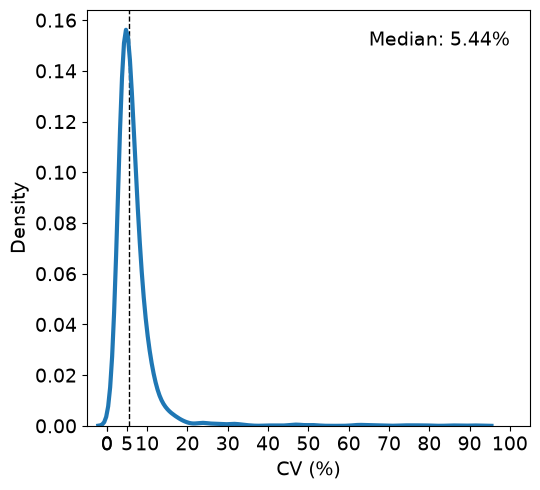

In [10]:
fig = plt.figure(figsize = [5.5, 5])

ax = sns.kdeplot(
    data=probe_cvs_lm[probe_cvs_lm.cv < 100],
    x="cv",
    linewidth = 3
)

plt.axvline(
    x = probe_cvs_lm[probe_cvs_lm.cv < 100].cv.median(),
    ymin = 0, ymax=1,
    linewidth = 1,
    linestyle = "dashed",
    color = "black",
    zorder = -1
)

plt.text(
    x = 100,
    y = 0.15,
    s = f"Median: {np.round(probe_cvs_lm[probe_cvs_lm.cv < 100].cv.median(), 2)}%",
    ha = "right",
    size = 14
)
plt.xticks([0, 5] + list(range(10, 110, 10)))

plt.xticks([0, 5] + list(range(0, 110, 10)))
plt.xlim(-5, 105)

plt.xlabel("CV (%)", size = 14)
plt.ylabel("Density", size = 14)
plt.tick_params(labelsize = 14)

plt.tight_layout()
plt.savefig("../results/2026_10_16_cv_through_linear_modeling/probe_cv_distribution_lm.svg")
plt.show()